# ASRO pilot - DINOv2-base (10-12 Nov 2026)

**Before you start:** Runtime -> Change runtime type -> **T4 GPU** -> Save; run each cell in order with **Shift+Enter** and wait for the green tick.

**Run order:** Cells **1 to 17** in order (Cell 17 zips and downloads all outputs). Cells 6-7 (randomised SVD), 15 and 16 (extra pictures) are optional.

| Cells | What they do |
|---|---|
| 1-4 | Setup, DINOv2-base, 32 Imagenette images (seed 0), read the token matrix X of every layer |
| 5 | Pilot v0: spectral concentration per layer |
| 6-7 | Randomised SVD vs exact SVD (layers 6 and 9) |
| 8 | Why layers 9-11 collapse: outlier tokens vs mean direction |
| 9 | Control: DINOv2 with registers |
| 10-11 | Figure 1a (detailed and proposal versions) |
| 12-14 | Where the outlier tokens are + Figure 1b (proposal) |
| 15-16 | Extra pictures for GitHub (optional) |
| 17 | Zip all outputs |

Colab forgets everything after closing or ~90 min idle: restart from Cell 1. Outputs go to the folder `asro_outputs` (folder icon on the left).

In [24]:
# Cell 1 - setup: install/import packages, set seed 0, choose GPU (run FIRST every day)
!pip -q install transformers torchvision matplotlib

import os, time, random, json, shutil
import numpy as np
import torch, torchvision, transformers
import matplotlib
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "/content/asro_outputs" if os.path.isdir("/content") else "asro_outputs"
DATA_DIR = "/content/data" if os.path.isdir("/content") else "data"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| transformers", transformers.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU - check Runtime -> Change runtime type")
print("outputs will be saved in:", OUT_DIR)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | transformers 5.22.1
device: cuda | Tesla T4
outputs will be saved in: /content/asro_outputs


In [25]:
# Cell 2 - load DINOv2-base (86M parameters) and its image processor from Hugging Face
from transformers import AutoImageProcessor, AutoModel

MODEL_NAME = "facebook/dinov2-base"
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

n_layers = len(model.encoder.layer)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Loaded {type(model).__name__}: {n_layers} layers, hidden size {model.config.hidden_size}, {n_params:.1f}M parameters")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loaded Dinov2Model: 12 layers, hidden size 768, 86.6M parameters


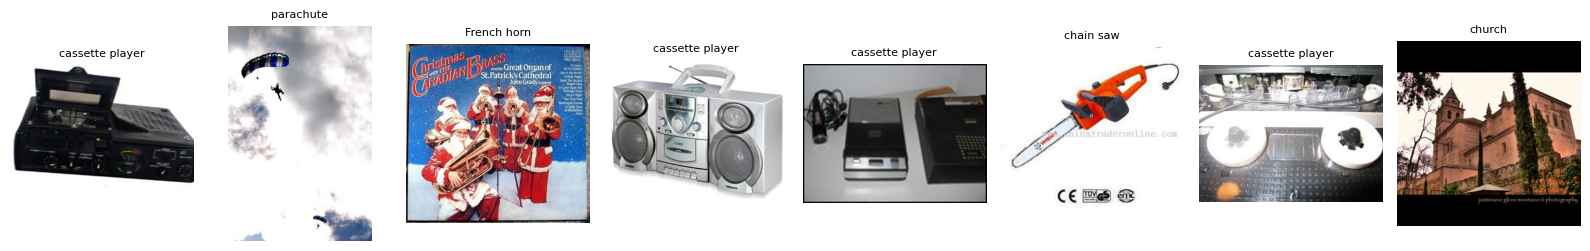

Validation images available: 3925 | picked 32 images (seed 0)
First 8 labels: ['cassette player', 'parachute', 'French horn', 'cassette player', 'cassette player', 'chain saw', 'cassette player', 'church']
Saved: /content/asro_outputs/sample_images.png


In [26]:
# Cell 3 - download Imagenette (10-class ImageNet subset, val split, 320px) and pick 32 fixed images
from torchvision.datasets import Imagenette

already = os.path.isdir(os.path.join(DATA_DIR, "imagenette2-320"))
ds = Imagenette(root=DATA_DIR, split="val", size="320px", download=not already)

N_IMAGES = 32
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(ds), generator=g)[:N_IMAGES].tolist()
images, labels = [], []
for i in idx:
    img, lab = ds[i]
    images.append(img.convert("RGB")); labels.append(int(lab))

def class_name(lab):
    c = ds.classes[lab]
    return c[0] if isinstance(c, (tuple, list)) else str(c)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, lab in zip(axes, images[:8], labels[:8]):
    ax.imshow(img); ax.set_title(class_name(lab), fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sample_images.png", dpi=120); plt.show()

print(f"Validation images available: {len(ds)} | picked {len(images)} images (seed {SEED})")
print("First 8 labels:", [class_name(l) for l in labels[:8]])
print("Saved:", f"{OUT_DIR}/sample_images.png")

In [27]:
# Cell 4 - forward hooks: capture the token representation H (tokens x 768) after every layer
def get_hidden_states(model, pixel_values):
    """Return a list (one per layer) of tensors [batch, tokens, hidden] captured by forward hooks."""
    store, handles = {}, []
    for i, layer in enumerate(model.encoder.layer):
        def hook(module, inputs, output, i=i):
            h = output[0] if isinstance(output, (tuple, list)) else output   # older transformers return a tuple
            store[i] = h.detach()
        handles.append(layer.register_forward_hook(hook))
    try:
        with torch.no_grad():
            model(pixel_values=pixel_values)
    finally:
        for h in handles:
            h.remove()          # always remove hooks, or they pile up each time you run the cell
    return [store[i] for i in range(len(model.encoder.layer))]

px = processor(images=images[:4], return_tensors="pt")["pixel_values"].to(device)
hs = get_hidden_states(model, px)
for i, h in enumerate(hs):
    print(f"layer {i:2d}: shape {tuple(h.shape)}")

# sanity check: hooks must agree with the model's own output_hidden_states
with torch.no_grad():
    ref = model(pixel_values=px, output_hidden_states=True).hidden_states
diff = max((hs[i] - ref[i + 1]).abs().max().item() for i in range(len(hs)))
print(f"pixel_values shape {tuple(px.shape)} | max difference hooks vs output_hidden_states = {diff:.2e} (should be ~0)")

layer  0: shape (4, 257, 768)
layer  1: shape (4, 257, 768)
layer  2: shape (4, 257, 768)
layer  3: shape (4, 257, 768)
layer  4: shape (4, 257, 768)
layer  5: shape (4, 257, 768)
layer  6: shape (4, 257, 768)
layer  7: shape (4, 257, 768)
layer  8: shape (4, 257, 768)
layer  9: shape (4, 257, 768)
layer 10: shape (4, 257, 768)
layer 11: shape (4, 257, 768)
pixel_values shape (4, 3, 224, 224) | max difference hooks vs output_hidden_states = 0.00e+00 (should be ~0)


Done in 6.7s for 32 images x 12 layers


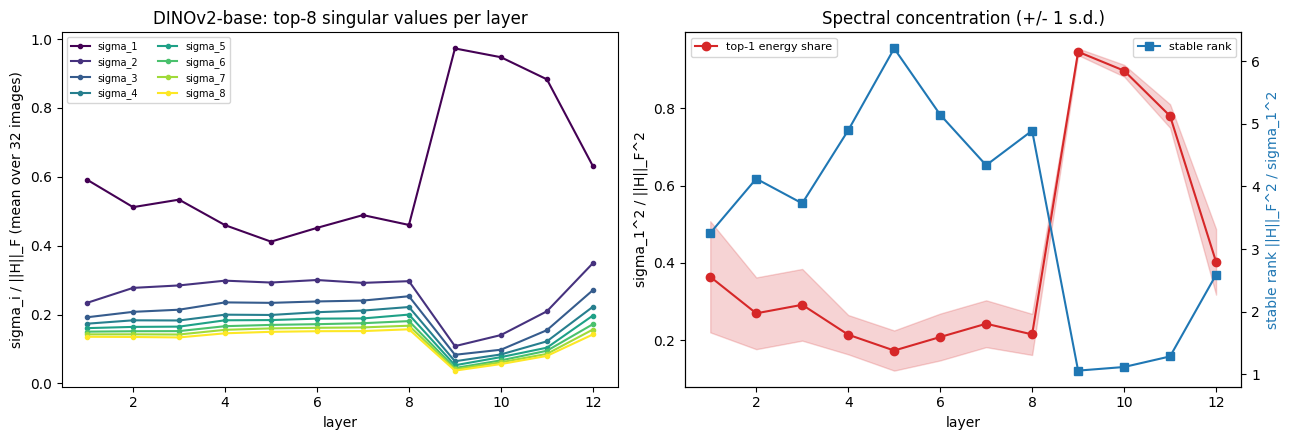

layer | sigma1/||H||F | top-1 energy | stable rank
    1 | 0.592         | 0.364        | 3.25
    2 | 0.512         | 0.269        | 4.12
    3 | 0.534         | 0.291        | 3.73
    4 | 0.460         | 0.214        | 4.90
    5 | 0.412         | 0.173        | 6.21
    6 | 0.452         | 0.208        | 5.15
    7 | 0.489         | 0.242        | 4.34
    8 | 0.460         | 0.215        | 4.89
    9 | 0.973         | 0.947        | 1.06
   10 | 0.947         | 0.898        | 1.11
   11 | 0.883         | 0.780        | 1.28
   12 | 0.631         | 0.403        | 2.59
Saved: /content/asro_outputs/pilot_v0.png and pilot_v0_mean_singular_values.csv, pilot_v0_results.json


In [28]:
# Cell 5 - PILOT v0: top-8 singular values of H for every layer, averaged over 32 images
K, BATCH = 8, 8
sv_topk, top1_energy, stable_rank = [], [], []
t0 = time.time()
for b in range(0, len(images), BATCH):
    px = processor(images=images[b:b + BATCH], return_tensors="pt")["pixel_values"].to(device)
    H = torch.stack(get_hidden_states(model, px), dim=1).float()   # [B, L, T, D]
    S = torch.linalg.svdvals(H)                                    # [B, L, min(T, D)], sorted descending
    fro2 = (S ** 2).sum(-1)                                        # ||H||_F^2
    sv_topk.append((S[..., :K] / fro2.sqrt().unsqueeze(-1)).cpu()) # sigma_i / ||H||_F
    top1_energy.append((S[..., 0] ** 2 / fro2).cpu())              # share of energy in direction 1
    stable_rank.append((fro2 / S[..., 0] ** 2).cpu())              # ||H||_F^2 / sigma_1^2
sv_topk = torch.cat(sv_topk)          # [N, L, K]
top1_energy = torch.cat(top1_energy)  # [N, L]
stable_rank = torch.cat(stable_rank)  # [N, L]
L = sv_topk.shape[1]
print(f"Done in {time.time() - t0:.1f}s for {sv_topk.shape[0]} images x {L} layers")

mean_sv = sv_topk.mean(0)
layers_x = np.arange(1, L + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cmap = matplotlib.colormaps["viridis"]
for k in range(K):
    ax[0].plot(layers_x, mean_sv[:, k].numpy(), marker="o", ms=3, color=cmap(k / (K - 1)), label=f"sigma_{k + 1}")
ax[0].set(xlabel="layer", ylabel="sigma_i / ||H||_F (mean over 32 images)", title="DINOv2-base: top-8 singular values per layer")
ax[0].legend(fontsize=7, ncol=2)
m, s = top1_energy.mean(0).numpy(), top1_energy.std(0).numpy()
ax[1].plot(layers_x, m, marker="o", color="tab:red", label="top-1 energy share")
ax[1].fill_between(layers_x, m - s, m + s, color="tab:red", alpha=0.2)
ax[1].set(xlabel="layer", ylabel="sigma_1^2 / ||H||_F^2", title="Spectral concentration (+/- 1 s.d.)")
ax2 = ax[1].twinx()
ax2.plot(layers_x, stable_rank.mean(0).numpy(), marker="s", color="tab:blue", label="stable rank")
ax2.set_ylabel("stable rank ||H||_F^2 / sigma_1^2", color="tab:blue")
ax[1].legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pilot_v0.png", dpi=150); plt.show()

np.savetxt(f"{OUT_DIR}/pilot_v0_mean_singular_values.csv", mean_sv.numpy(), delimiter=",",
           header=",".join(f"sigma{k + 1}_over_fro" for k in range(K)), comments="")
results = {"model": MODEL_NAME, "n_images": int(sv_topk.shape[0]), "seed": SEED, "k": K,
           "top1_energy_mean_per_layer": [round(float(v), 4) for v in m],
           "stable_rank_mean_per_layer": [round(float(v), 2) for v in stable_rank.mean(0)]}
json.dump(results, open(f"{OUT_DIR}/pilot_v0_results.json", "w"), indent=2)

print("layer | sigma1/||H||F | top-1 energy | stable rank")
for l in range(L):
    print(f"{l + 1:5d} | {mean_sv[l, 0]:.3f}         | {m[l]:.3f}        | {stable_rank[:, l].mean():.2f}")
print("Saved:", f"{OUT_DIR}/pilot_v0.png", "and pilot_v0_mean_singular_values.csv, pilot_v0_results.json")

(a) synthetic: max relative error of top-8 singular values = 1.75e-06
(b) my rSVD, power iterations=0: relative error sigma_1..8 = 5.8e-02 1.8e-01 1.7e-01 2.4e-01 2.5e-01 2.5e-01 3.1e-01 3.0e-01
(b) my rSVD, power iterations=1: relative error sigma_1..8 = 6.9e-05 1.2e-03 1.7e-02 1.0e-02 1.3e-02 1.6e-02 2.6e-02 1.3e-02
(b) my rSVD, power iterations=2: relative error sigma_1..8 = 1.2e-05 2.5e-05 1.4e-03 5.2e-04 1.0e-03 1.3e-03 2.5e-03 1.7e-03
(b) my rSVD, power iterations=4: relative error sigma_1..8 = 1.2e-05 1.1e-05 2.8e-05 3.5e-06 2.5e-05 2.6e-05 6.0e-05 8.1e-05
(b) torch.svd_lowrank(q=16, niter=2) max rel. error top-8 = 6.81e-03
(c) ||A - A_8||_F = 28.6213 | sqrt(sum_(i>8) sigma_i^2) = 28.6220 (should match)
(d) time per call on cuda: exact svdvals 28.52 ms | my rSVD 17.16 ms | svd_lowrank 10.27 ms


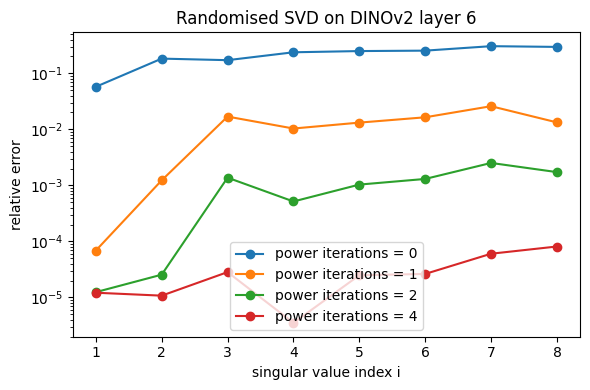

Saved: /content/asro_outputs/rsvd_study.png


In [29]:
# Cell 6 - STUDY: randomised SVD (Halko, Martinsson & Tropp 2011) vs exact SVD vs torch.svd_lowrank
def randomized_svd(A, k, p=8, n_iter=2, seed=0):
    """Basic HMT algorithm: random sketch -> power iterations -> QR -> small exact SVD."""
    gen = torch.Generator(device=A.device).manual_seed(seed)
    m, n = A.shape
    Omega = torch.randn(n, k + p, device=A.device, dtype=A.dtype, generator=gen)  # Gaussian test matrix
    Q, _ = torch.linalg.qr(A @ Omega)                     # orthonormal basis for the range of A
    for _ in range(n_iter):                               # power iterations sharpen a slowly decaying spectrum
        Q, _ = torch.linalg.qr(A.T @ Q)
        Q, _ = torch.linalg.qr(A @ Q)
    B = Q.T @ A                                           # small (k+p) x n matrix
    Ub, S, Vh = torch.linalg.svd(B, full_matrices=False)
    return (Q @ Ub)[:, :k], S[:k], Vh[:k].T

def timeit(fn, reps=5):
    fn()                                                  # warm-up
    if device == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(reps): fn()
    if device == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / reps * 1000

# (a) synthetic test with a KNOWN spectrum: sigma_i = 0.8^i
torch.manual_seed(SEED)
U0, _ = torch.linalg.qr(torch.randn(257, 257, device=device))
V0, _ = torch.linalg.qr(torch.randn(768, 257, device=device))
s_true = 0.8 ** torch.arange(257, device=device, dtype=torch.float32)
A_syn = U0 @ torch.diag(s_true) @ V0.T
_, s_r, _ = randomized_svd(A_syn, k=8)
print("(a) synthetic: max relative error of top-8 singular values =",
      f"{((s_r - s_true[:8]).abs() / s_true[:8]).max().item():.2e}")

# (b) real DINOv2 layer-6 token matrix of image 0
px = processor(images=images[:1], return_tensors="pt")["pixel_values"].to(device)
A = get_hidden_states(model, px)[5][0].float()            # [257, 768]
s_exact = torch.linalg.svdvals(A)
rows = []
for n_iter in [0, 1, 2, 4]:
    _, s_mine, _ = randomized_svd(A, k=8, p=8, n_iter=n_iter)
    rel = ((s_mine - s_exact[:8]).abs() / s_exact[:8]).cpu()
    rows.append((n_iter, rel))
    print(f"(b) my rSVD, power iterations={n_iter}: relative error sigma_1..8 =", " ".join(f"{v:.1e}" for v in rel))
torch.manual_seed(SEED)
_, s_tl, _ = torch.svd_lowrank(A, q=16, niter=2)
print("(b) torch.svd_lowrank(q=16, niter=2) max rel. error top-8 =",
      f"{((s_tl[:8] - s_exact[:8]).abs() / s_exact[:8]).max().item():.2e}")

# (c) Eckart-Young check: best rank-8 error = sqrt(sum of the remaining sigma_i^2)
Ue, Se, Vhe = torch.linalg.svd(A, full_matrices=False)
A8 = Ue[:, :8] @ torch.diag(Se[:8]) @ Vhe[:8]
print(f"(c) ||A - A_8||_F = {torch.linalg.norm(A - A8):.4f} | sqrt(sum_(i>8) sigma_i^2) = {Se[8:].pow(2).sum().sqrt():.4f} (should match)")

# (d) timing
print(f"(d) time per call on {device}: exact svdvals {timeit(lambda: torch.linalg.svdvals(A)):.2f} ms | "
      f"my rSVD {timeit(lambda: randomized_svd(A, 8)):.2f} ms | svd_lowrank {timeit(lambda: torch.svd_lowrank(A, q=16, niter=2)):.2f} ms")

plt.figure(figsize=(6, 4))
for n_iter, rel in rows:
    plt.semilogy(range(1, 9), rel.clamp_min(1e-12).numpy(), marker="o", label=f"power iterations = {n_iter}")
plt.xlabel("singular value index i"); plt.ylabel("relative error"); plt.title("Randomised SVD on DINOv2 layer 6")
plt.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rsvd_study.png", dpi=150); plt.show()
print("Saved:", f"{OUT_DIR}/rsvd_study.png")

In [30]:
# Cell 7 - SAVE the randomised SVD study as CSV, for layers 6 AND 9, on all 32 images
# (run after Cell 6; uses randomized_svd() from Cell 6 and get_hidden_states() from Cell 4)
import pandas as pd
px_all = processor(images=images, return_tensors="pt")["pixel_values"].to(device)
hs = get_hidden_states(model, px_all)                     # hs[l-1] = layer l, shape [32, 257, 768]
rows = []
for layer in [6, 9]:
    H_l = hs[layer - 1]
    for b in range(H_l.shape[0]):
        A = H_l[b].float()                                # token matrix of one image [257, 768]
        _, S_ex, Vh_ex = torch.linalg.svd(A, full_matrices=False)
        for n_iter in [0, 1, 2, 4]:
            _, s_r, V_r = randomized_svd(A, k=8, p=8, n_iter=n_iter, seed=b)
            rel = ((s_r - S_ex[:8]).abs() / S_ex[:8])
            rows.append(dict(layer=layer, image=b, power_iterations=n_iter,
                             max_rel_err_sigma_1to8=rel.max().item(),
                             rel_err_sigma1=rel[0].item(),
                             cos_v1=abs(torch.dot(Vh_ex[0], V_r[:, 0])).item()))   # 1.0 = top direction found exactly
df_rsvd = pd.DataFrame(rows)
df_rsvd.to_csv(f"{OUT_DIR}/rsvd_study_per_image.csv", index=False)
summary = (df_rsvd.groupby(["layer", "power_iterations"])
           .agg(max_rel_err_worst=("max_rel_err_sigma_1to8", "max"),
                max_rel_err_mean=("max_rel_err_sigma_1to8", "mean"),
                cos_v1_min=("cos_v1", "min"))
           .reset_index())
summary.to_csv(f"{OUT_DIR}/rsvd_study_summary.csv", index=False)
pd.set_option("display.float_format", lambda v: f"{v:.2e}")
print(summary.to_string(index=False))
print("Saved:", f"{OUT_DIR}/rsvd_study_per_image.csv", "and", f"{OUT_DIR}/rsvd_study_summary.csv")
# For the proposal: read the row layer=9, power_iterations=2.
#  max_rel_err_worst = worst error over all 32 images (use this number, e.g. 0.003 = 0.3%)
#  cos_v1_min close to 1.0 means the top direction is found correctly in every image

 layer  power_iterations  max_rel_err_worst  max_rel_err_mean  cos_v1_min
     6                 0           3.81e-01          3.13e-01    9.72e-01
     6                 1           9.34e-02          4.65e-02    1.00e+00
     6                 2           3.51e-02          9.53e-03    1.00e+00
     6                 4           4.09e-03          6.54e-04    1.00e+00
     9                 0           3.66e-01          2.78e-01    1.00e+00
     9                 1           8.27e-02          3.60e-02    1.00e+00
     9                 2           2.01e-02          6.08e-03    1.00e+00
     9                 4           1.16e-03          2.21e-04    1.00e+00
Saved: /content/asro_outputs/rsvd_study_per_image.csv and /content/asro_outputs/rsvd_study_summary.csv


In [31]:
# Cell 8 - DIAGNOSE the layer-9 jump: outlier tokens? mean direction? CLS?
# Run after Cells 1-4. Uses the same 32 images.
rows = []
for b in range(0, len(images), 8):
    px = processor(images=images[b:b + 8], return_tensors="pt")["pixel_values"].to(device)
    H = torch.stack(get_hidden_states(model, px), dim=1).float()      # [B, L, T, D]
    norms = H.norm(dim=-1)                                            # [B, L, T] token norms
    med = norms.median(dim=-1).values                                 # [B, L]
    top_ratio = norms.max(dim=-1).values / med                        # biggest token vs typical token
    n_big = (norms > 10 * med.unsqueeze(-1)).sum(-1).float()          # tokens > 10x the median norm
    big_idx = norms.argmax(dim=-1)                                    # which token is biggest (0 = CLS)

    def srank(X):
        S = torch.linalg.svdvals(X)
        return (S ** 2).sum(-1) / S[..., 0] ** 2

    sr_raw = srank(H)                                                 # same as Cell 5
    sr_centered = srank(H - H.mean(dim=2, keepdim=True))              # remove the mean token
    sr_noCLS = srank(H[:, :, 1:, :])                                  # drop CLS token
    # drop the high-norm outlier tokens (> 10x median) by zeroing them
    keep = (norms <= 10 * med.unsqueeze(-1)).unsqueeze(-1).float()
    sr_noOutliers = srank(H * keep)
    rows.append(torch.stack([top_ratio, n_big, (big_idx == 0).float(), sr_raw, sr_centered, sr_noCLS, sr_noOutliers], -1).cpu())

R = torch.cat(rows).mean(0)                                           # [L, 7] averaged over images
names = ["maxnorm/median", "#tokens>10x", "biggest=CLS", "sr raw", "sr centred", "sr no CLS", "sr no outliers"]
print("layer | " + " | ".join(names))
for l in range(R.shape[0]):
    print(f"{l + 1:5d} | " + " | ".join(f"{v:8.2f}" for v in R[l].tolist()))
np.savetxt(f"{OUT_DIR}/pilot_v0_diagnostics.csv", R.numpy(), delimiter=",", header=",".join(names), comments="")
print("Saved:", f"{OUT_DIR}/pilot_v0_diagnostics.csv")

layer | maxnorm/median | #tokens>10x | biggest=CLS | sr raw | sr centred | sr no CLS | sr no outliers
    1 |     2.16 |     0.00 |     0.00 |     3.25 |    11.62 |     3.25 |     3.25
    2 |     1.83 |     0.00 |     0.28 |     4.12 |     9.74 |     4.09 |     4.12
    3 |     1.91 |     0.00 |     1.00 |     3.73 |     8.66 |     3.68 |     3.73
    4 |     1.94 |     0.00 |     1.00 |     4.90 |     8.79 |     4.84 |     4.90
    5 |     2.59 |     0.00 |     1.00 |     6.21 |     9.60 |     6.16 |     6.21
    6 |     1.52 |     0.00 |     0.31 |     5.15 |     8.58 |     5.14 |     5.15
    7 |     2.35 |     0.00 |     0.28 |     4.34 |     8.70 |     4.30 |     4.34
    8 |     2.85 |     0.00 |     0.06 |     4.89 |     8.80 |     4.88 |     4.89
    9 |    52.90 |     3.34 |     0.00 |     1.06 |     1.05 |     1.06 |     4.12
   10 |    34.50 |     3.25 |     0.00 |     1.11 |     1.10 |     1.11 |     4.29
   11 |    20.86 |     2.75 |     0.00 |     1.28 |     1.24 |     1

In [32]:
# Cell 9 - CONTROL: same diagnosis on DINOv2-base WITH REGISTERS (expect no layer-9 jump)
# Run after Cells 1-4 and Cell 8. Loads a second model; the first model stays loaded.
from transformers import AutoImageProcessor, AutoModel
REG_NAME = "facebook/dinov2-with-registers-base"
proc_reg = AutoImageProcessor.from_pretrained(REG_NAME)
model_reg = AutoModel.from_pretrained(REG_NAME).to(device).eval()
n_reg = getattr(model_reg.config, "num_register_tokens", 0)
print(f"Loaded {type(model_reg).__name__}: {len(model_reg.encoder.layer)} layers, {n_reg} register tokens")

def srank(X):
    S = torch.linalg.svdvals(X)
    return (S ** 2).sum(-1) / S[..., 0] ** 2

rows = []
for b in range(0, len(images), 8):
    px = proc_reg(images=images[b:b + 8], return_tensors="pt")["pixel_values"].to(device)
    H_all = torch.stack(get_hidden_states(model_reg, px), dim=1).float()   # [B, L, 1+n_reg+256, D]
    H = H_all[:, :, 1 + n_reg:, :]                                          # patch tokens only
    norms = H.norm(dim=-1); med = norms.median(dim=-1).values
    rows.append(torch.stack([norms.max(-1).values / med,
                             (norms > 10 * med.unsqueeze(-1)).sum(-1).float(),
                             srank(H), srank(H - H.mean(dim=2, keepdim=True))], -1).cpu())
R2 = torch.cat(rows).mean(0)
names2 = ["maxnorm/median", "#tokens>10x", "sr patches", "sr patches centred"]
print("layer | " + " | ".join(names2))
for l in range(R2.shape[0]):
    print(f"{l + 1:5d} | " + " | ".join(f"{v:8.2f}" for v in R2[l].tolist()))
np.savetxt(f"{OUT_DIR}/pilot_v0_registers_control.csv", R2.numpy(), delimiter=",", header=",".join(names2), comments="")
print("Saved:", f"{OUT_DIR}/pilot_v0_registers_control.csv")

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

Loaded Dinov2WithRegistersModel: 12 layers, 4 register tokens
layer | maxnorm/median | #tokens>10x | sr patches | sr patches centred
    1 |     1.83 |     0.00 |     2.34 |     8.73
    2 |     1.59 |     0.00 |     2.51 |     7.18
    3 |     1.47 |     0.00 |     2.94 |     7.12
    4 |     1.35 |     0.00 |     2.82 |     7.32
    5 |     1.36 |     0.00 |     3.48 |     8.04
    6 |     1.28 |     0.00 |     4.01 |     8.54
    7 |     1.32 |     0.00 |     4.18 |     8.80
    8 |     1.30 |     0.00 |     4.28 |     7.82
    9 |     1.30 |     0.00 |     4.30 |     8.45
   10 |     1.36 |     0.00 |     4.78 |     7.55
   11 |     1.43 |     0.00 |     4.08 |     5.98
   12 |     1.26 |     0.00 |     1.81 |     3.86
Saved: /content/asro_outputs/pilot_v0_registers_control.csv


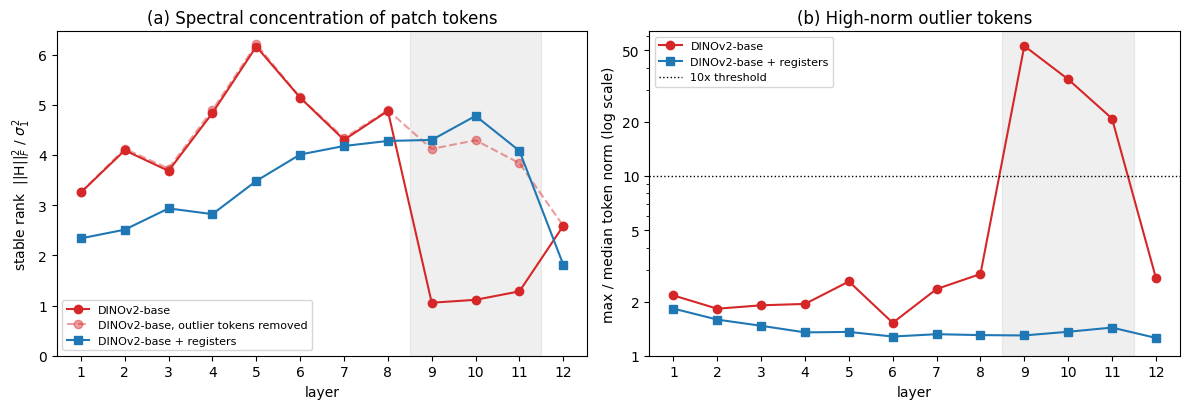

Saved: /content/asro_outputs/fig_prelim_concentration.png


In [33]:
# Cell 10 - PROPOSAL VERSION of the figure (same data, clearer labels)
from matplotlib.ticker import ScalarFormatter
d = np.loadtxt(f"{OUT_DIR}/pilot_v0_diagnostics.csv", delimiter=",", skiprows=1)
r = np.loadtxt(f"{OUT_DIR}/pilot_v0_registers_control.csv", delimiter=",", skiprows=1)
x = np.arange(1, d.shape[0] + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a in ax:
    a.axvspan(8.5, 11.5, color="grey", alpha=0.12)           # shade the collapse layers 9-11
    a.set_xticks(x); a.set_xlabel("layer")
ax[0].plot(x, d[:, 5], "o-", color="tab:red", label="DINOv2-base")
ax[0].plot(x, d[:, 6], "o--", color="tab:red", alpha=0.45, label="DINOv2-base, outlier tokens removed")
ax[0].plot(x, r[:, 2], "s-", color="tab:blue", label="DINOv2-base + registers")
ax[0].set(ylabel="stable rank  ||H||$_F^2$ / $\\sigma_1^2$", title="(a) Spectral concentration of patch tokens", ylim=(0, None))
ax[0].legend(fontsize=8, loc="lower left")
ax[1].plot(x, d[:, 0], "o-", color="tab:red", label="DINOv2-base")
ax[1].plot(x, r[:, 0], "s-", color="tab:blue", label="DINOv2-base + registers")
ax[1].axhline(10, color="k", ls=":", lw=1, label="10x threshold")
ax[1].set_yscale("log"); ax[1].set_yticks([1, 2, 5, 10, 20, 50])
ax[1].yaxis.set_major_formatter(ScalarFormatter())
ax[1].set(ylabel="max / median token norm (log scale)", title="(b) High-norm outlier tokens")
ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_prelim_concentration.png", dpi=200); plt.show()
print("Saved:", f"{OUT_DIR}/fig_prelim_concentration.png")

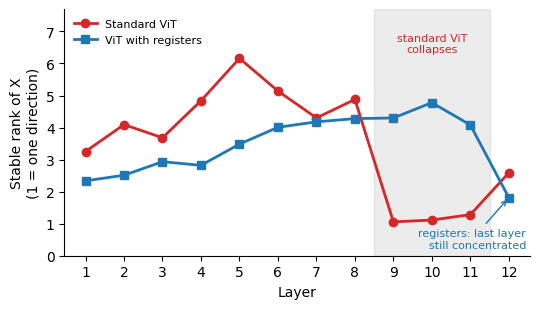

Saved: /content/asro_outputs/fig1_proposal_simple.png


In [34]:
# Cell 11 - SIMPLE proposal figure: one panel, two lines (standard vs registers)
d = np.loadtxt(f"{OUT_DIR}/pilot_v0_diagnostics.csv", delimiter=",", skiprows=1)
r = np.loadtxt(f"{OUT_DIR}/pilot_v0_registers_control.csv", delimiter=",", skiprows=1)
x = np.arange(1, d.shape[0] + 1)
sr_std, sr_reg = d[:, 5], r[:, 2]                    # stable rank per layer (same columns as Cell 10)

fig, ax = plt.subplots(figsize=(5.5, 3.2))            # about half a page wide
ax.axvspan(8.5, 11.5, color="grey", alpha=0.15)       # shade layers 9-11
ax.plot(x, sr_std, "o-", color="tab:red", lw=2, label="Standard ViT")
ax.plot(x, sr_reg, "s-", color="tab:blue", lw=2, label="ViT with registers")
top = max(sr_std.max(), sr_reg.max())
ax.text(10, top * 1.02, "standard ViT\ncollapses", ha="center", va="bottom", fontsize=8, color="tab:red")
ax.annotate("registers: last layer\nstill concentrated", xy=(x[-1], sr_reg[-1]),
            xytext=(x[-1] + 0.45, top * 0.03), ha="right", va="bottom", fontsize=8, color="tab:blue",
            arrowprops=dict(arrowstyle="->", lw=1, color="tab:blue"))
ax.set_xticks(x); ax.set_xlabel("Layer")
ax.set_ylabel("Stable rank of X\n(1 = one direction)")
ax.set_ylim(0, top * 1.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig1_proposal_simple.png", dpi=300); plt.show()
print("Saved:", f"{OUT_DIR}/fig1_proposal_simple.png")

## Added 12 Nov 2026 - where are the outlier tokens? (Cells 12-16)

Run after Cells 1-4 (Cells 5-11 are not needed for this part). Same 32 images as Figure 1a, so all pilot numbers come from one data set.

- **Cell 12** finds the high-norm patch tokens (> 10x median) at layers 9, 10, 11.
- **Cell 13** checks *where* they are: the top-left token, plain (redundant) patches, border, same patches across layers.
- **Cell 14** makes the small proposal figure `fig1b_tiny.png` (Figure 1b): two images without people.
- **Cell 15** (optional) shows the outlier map on 16 images and a similarity histogram.
- **Cell 16** (optional) makes a detailed Figure 1b with a bar chart, for GitHub or talks.

In [35]:
# Cell 12 - OUTLIER-TOKEN MAP: which patch tokens are > 10x the median norm (layers 9-11)?
# Run after Cells 1-4. Uses get_hidden_states() from Cell 4 and the same 32 images.
PATCH = model.config.patch_size
px_all = processor(images=images, return_tensors="pt")["pixel_values"].to(device)
hs = get_hidden_states(model, px_all)                     # hs[l-1] = layer l, shape [32, 257, 768]
Hh, Ww = px_all.shape[-2] // PATCH, px_all.shape[-1] // PATCH
n_front = hs[0].shape[1] - Hh * Ww                       # CLS token(s) at the front
outl, ratio = {}, {}
print("layer | mean # outliers per image | max/median norm (mean)")
for layer in [6, 8, 9, 10, 11, 12]:
    pn = hs[layer - 1][:, n_front:, :].float().norm(dim=-1).cpu().numpy()   # [32, 256] patch norms
    r = pn / np.median(pn, axis=1, keepdims=True)
    ratio[layer] = r.reshape(-1, Hh, Ww)
    outl[layer] = ratio[layer] > 10
    print(f"{layer:5d} | {outl[layer].sum(axis=(1, 2)).mean():25.2f} | {r.max(axis=1).mean():8.1f}")
print("expected: ~0 outliers at layers 6, 8, 12 and ~3 per image at layers 9-11")

layer | mean # outliers per image | max/median norm (mean)
    6 |                      0.00 |      1.5
    8 |                      0.00 |      2.8
    9 |                      3.34 |     52.9
   10 |                      3.25 |     34.5
   11 |                      2.75 |     20.9
   12 |                      0.00 |      2.7
expected: ~0 outliers at layers 6, 8, 12 and ~3 per image at layers 9-11


In [36]:
# Cell 13 - WHERE are they? top-left token, plain patches, border, same patches across layers
# redundancy of a patch = mean cosine similarity of its (mean-removed) pixels to its 4 neighbours (1 = plain area)
mean_ = torch.tensor(processor.image_mean).view(1, 3, 1, 1)
std_ = torch.tensor(processor.image_std).view(1, 3, 1, 1)
imgs = (px_all.cpu().float() * std_ + mean_).clamp(0, 1)                     # images as the model sees them
P = imgs.unfold(2, PATCH, PATCH).unfold(3, PATCH, PATCH).permute(0, 2, 3, 1, 4, 5).reshape(len(images), Hh, Ww, -1)
P = P - P.mean(-1, keepdim=True); P = P / (P.norm(dim=-1, keepdim=True) + 1e-6)
red = torch.zeros(len(images), Hh, Ww); cnt = torch.zeros(1, Hh, Ww)
for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
    valid = torch.ones(1, Hh, Ww)
    if dy == -1: valid[:, -1, :] = 0
    if dy == 1: valid[:, 0, :] = 0
    if dx == -1: valid[:, :, -1] = 0
    if dx == 1: valid[:, :, 0] = 0
    red += (P * torch.roll(P, shifts=(dy, dx), dims=(1, 2))).sum(-1) * valid; cnt += valid
red = (red / cnt).numpy()
border = np.zeros((Hh, Ww), bool); border[:2, :] = border[-2:, :] = border[:, :2] = border[:, -2:] = True

rows = []
for layer in [9, 10, 11]:
    m = outl[layer]; mc = m.copy(); mc[:, 0, 0] = False                       # mc = outliers without the top-left token
    rows.append(dict(layer=layer,
                     corner_is_outlier_share=float(m[:, 0, 0].mean()),
                     outliers_per_image_without_corner=float(mc.sum() / len(images)),
                     redundancy_outliers_without_corner=float(red[mc].mean()) if mc.sum() else float("nan"),
                     redundancy_other_patches=float(red[~m].mean()),
                     border_share_without_corner=float(border[None].repeat(len(images), 0)[mc].mean()) if mc.sum() else float("nan"),
                     border_area_share=float(border.mean())))
def jacc(a, b):
    u = (a | b).sum(); return (a & b).sum() / u if u else np.nan
for (a, b) in [(9, 10), (10, 11), (9, 11)]:
    rows.append(dict(layer=f"jaccard {a}-{b}", jaccard_same_patches=float(np.nanmean([jacc(outl[a][i], outl[b][i]) for i in range(len(images))]))))
import pandas as pd
df_loc = pd.DataFrame(rows); df_loc.to_csv(f"{OUT_DIR}/pilot_v0_outlier_location.csv", index=False)
print(df_loc.round(3).to_string(index=False))
print("Saved:", f"{OUT_DIR}/pilot_v0_outlier_location.csv")
print("expected (12 Nov run): corner share 1.00; redundancy ~0.67 vs ~0.42; border share below area share; Jaccard ~0.9")

        layer  corner_is_outlier_share  outliers_per_image_without_corner  redundancy_outliers_without_corner  redundancy_other_patches  border_share_without_corner  border_area_share  jaccard_same_patches
            9                 1.00e+00                           2.34e+00                            5.08e-01                  3.72e-01                     3.87e-01           4.38e-01                   NaN
           10                 1.00e+00                           2.25e+00                            5.09e-01                  3.72e-01                     3.89e-01           4.38e-01                   NaN
           11                 1.00e+00                           1.75e+00                            5.24e-01                  3.73e-01                     4.29e-01           4.38e-01                   NaN
 jaccard 9-10                      NaN                                NaN                                 NaN                       NaN                          NaN            

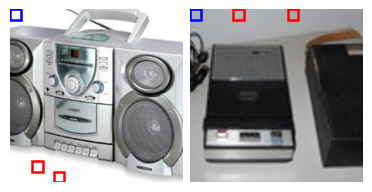

images shown: ['cassette player', 'cassette player'] (indices [3, 4] )
Saved: /content/asro_outputs/fig1b_tiny.png and .pdf


In [37]:
# Cell 14 - Figure 1b for the proposal (tiny, two images without people), blue = top-left token, red = other outliers
import matplotlib.patches
names = [class_name(l) for l in labels]
SHOW = [3, 4]          # cassette player (white background) + cassette recorder (grey surface)
fig, axes = plt.subplots(1, 2, figsize=(3.6, 2.0))
for ax, k in zip(axes, SHOW):
    ax.imshow(imgs[k].permute(1, 2, 0).numpy())
    for r_, c_ in zip(*np.nonzero(m[k])):
        col = "blue" if (r_, c_) == (0, 0) else "red"
        ax.add_patch(matplotlib.patches.Rectangle((c_ * PATCH, r_ * PATCH), PATCH, PATCH, fill=False, ec=col, lw=1.8))
    ax.axis("off")
plt.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01, wspace=0.04)
plt.savefig(f"{OUT_DIR}/fig1b_tiny.png", dpi=300); plt.savefig(f"{OUT_DIR}/fig1b_tiny.pdf"); plt.show()
print("images shown:", [names[k] for k in SHOW], "(indices", SHOW, ")")
print("Saved:", f"{OUT_DIR}/fig1b_tiny.png and .pdf")

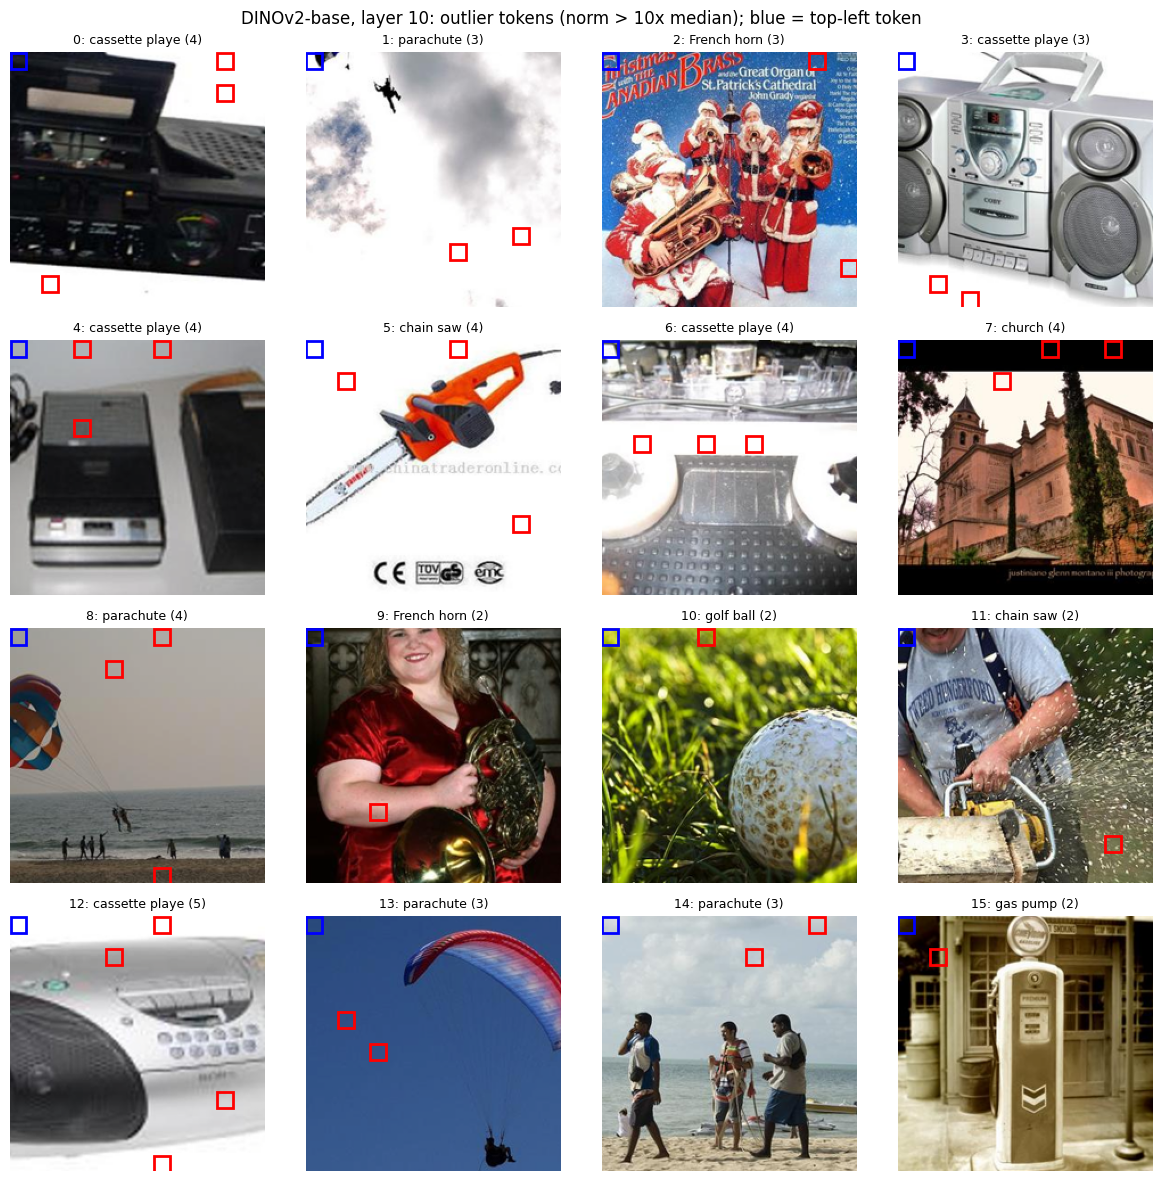

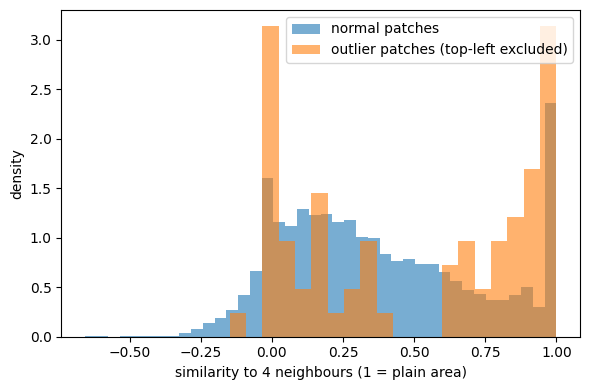

Saved: /content/asro_outputs/fig_outlier_map_L10.png and fig_outlier_similarity_L10.png


In [38]:
# Cell 15 - outlier map on 16 images (layer 10) + similarity histogram (for GitHub, not the proposal)
# What this cell does and why: lets you SEE all outliers at once (blue = top-left token, red = others)
# and compare how "plain" outlier patches are versus normal patches.
import matplotlib.patches as mpatches
names = [class_name(l) for l in labels]
m = outl[10]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(imgs[k].permute(1, 2, 0).numpy()); ax.axis("off")
    for r_, c_ in zip(*np.nonzero(m[k])):
        ax.add_patch(mpatches.Rectangle((c_ * PATCH, r_ * PATCH), PATCH, PATCH, fill=False,
                                        ec="blue" if (r_, c_) == (0, 0) else "red", lw=2))
    ax.set_title(f"{k}: {names[k][:14]} ({m[k].sum()})", fontsize=9)
fig.suptitle("DINOv2-base, layer 10: outlier tokens (norm > 10x median); blue = top-left token")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_outlier_map_L10.png", dpi=200); plt.show()

mc = m.copy(); mc[:, 0, 0] = False
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(red[~m], bins=40, density=True, alpha=0.6, label="normal patches")
if mc.sum(): ax.hist(red[mc], bins=20, density=True, alpha=0.6, label="outlier patches (top-left excluded)")
ax.set_xlabel("similarity to 4 neighbours (1 = plain area)"); ax.set_ylabel("density"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_outlier_similarity_L10.png", dpi=200); plt.show()
print("Saved:", f"{OUT_DIR}/fig_outlier_map_L10.png and fig_outlier_similarity_L10.png")

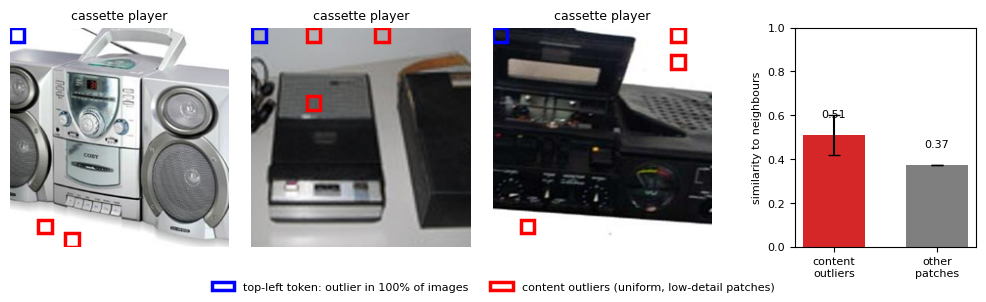

content outliers: 72 | similarity 0.51 (95% CI 0.42-0.60) vs others 0.37
Saved: /content/asro_outputs/fig1b_detailed.png and .pdf


In [39]:
# Cell 16 - detailed Figure 1b (3 images + bar chart with 95% CI) - for GitHub / talks, not the proposal
# What this cell does and why: one picture with both kinds of outliers and the similarity result.
rng_b = np.random.default_rng(SEED)
def boot_ci(x, B=2000):
    x = np.asarray(x)
    if len(x) == 0: return (np.nan, np.nan)
    mm = [rng_b.choice(x, len(x)).mean() for _ in range(B)]
    return np.percentile(mm, 2.5), np.percentile(mm, 97.5)
m = outl[10]; mc = m.copy(); mc[:, 0, 0] = False
lo, hi = boot_ci(red[mc]); vals = [red[mc].mean(), red[~m].mean()]
SHOW3 = SHOW + [i for i in range(len(images)) if i not in SHOW][:3 - len(SHOW)]
fig = plt.figure(figsize=(10, 3.0))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 0.22, 0.8], wspace=0.08)
for j, k in enumerate(SHOW3):
    ax = fig.add_subplot(gs[0, j]); ax.imshow(imgs[k].permute(1, 2, 0).numpy()); ax.axis("off")
    for r_, c_ in zip(*np.nonzero(m[k])):
        ax.add_patch(mpatches.Rectangle((c_ * PATCH, r_ * PATCH), PATCH, PATCH, fill=False,
                                        ec="blue" if (r_, c_) == (0, 0) else "red", lw=2.5))
    ax.set_title(names[k], fontsize=9)
ax = fig.add_subplot(gs[0, 4])
ax.bar([0, 1], vals, color=["tab:red", "tab:gray"], width=0.6, yerr=[[vals[0] - lo, 0], [hi - vals[0], 0]], capsize=4)
ax.set_xticks([0, 1]); ax.set_xticklabels(["content\noutliers", "other\npatches"], fontsize=8)
ax.set_ylabel("similarity to neighbours", fontsize=8); ax.set_ylim(0, 1); ax.tick_params(labelsize=8)
for x, v in zip([0, 1], vals): ax.text(x, v + 0.08, f"{v:.2f}", ha="center", fontsize=8)
handles = [mpatches.Patch(fill=False, ec="blue", lw=2.5, label=f"top-left token: outlier in {m[:, 0, 0].mean():.0%} of images"),
           mpatches.Patch(fill=False, ec="red", lw=2.5, label="content outliers (uniform, low-detail patches)")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=8, frameon=False)
plt.subplots_adjust(bottom=0.17, top=0.9, left=0.02, right=0.99)
plt.savefig(f"{OUT_DIR}/fig1b_detailed.png", dpi=300); plt.savefig(f"{OUT_DIR}/fig1b_detailed.pdf"); plt.show()
print(f"content outliers: {mc.sum()} | similarity {vals[0]:.2f} (95% CI {lo:.2f}-{hi:.2f}) vs others {vals[1]:.2f}")
print("Saved:", f"{OUT_DIR}/fig1b_detailed.png and .pdf")

In [40]:
# Cell 17 - zip ALL outputs (run LAST, after Cell 16) and download
zip_path = shutil.make_archive(OUT_DIR + "_all", "zip", OUT_DIR)
print("Files in", OUT_DIR, ":")
for f in sorted(os.listdir(OUT_DIR)):
    print("   ", f)
print("Zip file ready:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Not in Colab (or download blocked): folder icon on the left -> right-click the zip -> Download")

Files in /content/asro_outputs :
    fig1_proposal_simple.png
    fig1b_detailed.pdf
    fig1b_detailed.png
    fig1b_tiny.pdf
    fig1b_tiny.png
    fig_outlier_map_L10.png
    fig_outlier_similarity_L10.png
    fig_prelim_concentration.png
    pilot_v0.png
    pilot_v0_diagnostics.csv
    pilot_v0_mean_singular_values.csv
    pilot_v0_outlier_location.csv
    pilot_v0_registers_control.csv
    pilot_v0_results.json
    rsvd_study.png
    rsvd_study_per_image.csv
    rsvd_study_summary.csv
    sample_images.png
Zip file ready: /content/asro_outputs_all.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>